# Regressione logistica con selezione AIC/BIC e variabili derivate
Stessa procedura della regressione ricevuta (forward e backward, AIC e BIC, modello finale scelto col BIC), con due differenze:
1. **`fit_logit` corretta**: l'intercetta `const` non viene più scartata (prima era una colonna costante e finiva eliminata, quindi la selezione era fatta su modelli senza intercetta);
2. **variabili derivate in più**, confrontando il modello senza e con queste.

Variabili aggiunte (statistiche calcolate **solo sul train**):
- `cgpa_rel_semestre` = `CGPA` meno la media dei CGPA dello stesso semestre;
- `costo_rel` = `Cost_without_study` diviso la mediana del costo della stessa `Family_background`;
- `isolato` = 1 se vive da solo (`Bachelor`) **e** non ha amici.

`eta_vs_semestre` (= `Age - Current_semester`) qui **non si può usare**: in un modello lineare è una combinazione esatta di `Age` e `Current_semester`, quindi non aggiunge informazione e rende la matrice singolare. Per l'albero invece serviva, perché l'albero non fa differenze tra colonne.

In [12]:
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
import sklearn.metrics as skl_metr

pd.set_option("display.width", 1000)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: "%.3f" % x)

FILE_CSV = "/Users/ale/Desktop/CRIF SETTIMANA 3/Student_Depression_Dataset.csv"
RANDOM_STATE = 42
TARGET = "Depression"

num_cols = ["Age", "Current_semester", "CGPA", "Cost_without_study"]
cat_cols = ["Gender", "Family_background", "Relationship_status", "Marital_status", "Living_style", "friend_circle", "Home_division"]
excluded_cols = ["Health_condition"]   # separa quasi perfettamente il target (leakage)

df = pd.read_csv(FILE_CSV)
df[TARGET] = df[TARGET].astype(str).str.strip().str.lower().map({"yes": 1, "no": 0})
assert df[TARGET].notna().all()
df[TARGET] = df[TARGET].astype(int)
df = df[[TARGET] + num_cols + cat_cols].dropna().copy()
print(df.shape, df[TARGET].mean())

(4464, 12) 0.26904121863799285


### Split
Stesso `random_state` e `stratify`: gli studenti nel test sono gli stessi delle altre analisi.

In [13]:
train_df, test_df = train_test_split(df, test_size=0.20, random_state=RANDOM_STATE, stratify=df[TARGET])
print("Train:", train_df.shape, "Test:", test_df.shape)
print(train_df[TARGET].mean().round(3), test_df[TARGET].mean().round(3))

Train: (3571, 12) Test: (893, 12)
0.269 0.269


### Variabili derivate
Le statistiche di riferimento (media CGPA per semestre, mediana costo per classe sociale) si calcolano sul train e si applicano a train e test. Questo va fatto **prima** della standardizzazione, sui valori originali.

In [14]:
media_cgpa_sem = train_df.groupby("Current_semester")["CGPA"].mean()
mediana_costo_fam = train_df.groupby("Family_background")["Cost_without_study"].median()

def aggiungi_feature(d):
    d = d.copy()
    d["cgpa_rel_semestre"] = d["CGPA"] - d["Current_semester"].clip(media_cgpa_sem.index.min(), media_cgpa_sem.index.max()).map(media_cgpa_sem)   # semestre mai visto nel train -> il piu' vicino
    d["costo_rel"] = d["Cost_without_study"] / d["Family_background"].map(mediana_costo_fam)
    d["isolato"] = ((d["Living_style"] == "Bachelor") & (d["friend_circle"] == "No")).astype(int)
    return d

train_df = aggiungi_feature(train_df)
test_df = aggiungi_feature(test_df)

NUOVE = ["cgpa_rel_semestre", "costo_rel", "isolato"]
num_cols_all = num_cols + ["cgpa_rel_semestre", "costo_rel"]   # isolato e' binaria: non si standardizza
train_df[NUOVE].describe()

,cgpa_rel_semestre,costo_rel,isolato
count,3571.000,3571.000,3571.000
mean,-0.000,0.988,0.137
std,0.387,0.449,0.344
min,-1.211,0.000,0.000
25%,-0.261,0.627,0.000
50%,0.069,1.000,0.000
75%,0.300,1.311,0.000
max,0.644,4.918,1.000


### Standardizzazione e dummy
Come nell'originale: scaler stimato solo sul train, `get_dummies` con `drop_first=True`, colonne del test allineate al train.

In [15]:
scaler = StandardScaler()
train_df[num_cols_all] = scaler.fit_transform(train_df[num_cols_all])
test_df[num_cols_all] = scaler.transform(test_df[num_cols_all])

def costruisci_X(d):
    X = pd.get_dummies(d[num_cols_all + ["isolato"] + cat_cols], columns=cat_cols, drop_first=True, dtype=float)
    return X

train_X = costruisci_X(train_df)
test_X = costruisci_X(test_df).reindex(columns=train_X.columns, fill_value=0)

y_train = train_df[TARGET].astype(int)
y_test = test_df[TARGET].astype(int)

X_train = sm.add_constant(train_X, has_constant="add")
X_test = sm.add_constant(test_X, has_constant="add")

POOL_BASE = [c for c in X_train.columns if c != "const" and c not in NUOVE]
POOL_NUOVO = [c for c in X_train.columns if c != "const"]
print(X_train.shape, X_test.shape)
print("variabili base:", len(POOL_BASE), "- con nuove:", len(POOL_NUOVO))

(3571, 24) (893, 24)
variabili base: 20 - con nuove: 23


### Funzioni
`fit_logit` mantiene sempre `const` e rifiuta le matrici non a rango pieno (collineari). Il resto è identico all'originale, con un parametro `pool` che dice da quali variabili si può scegliere.

In [16]:
def fit_logit(X, y):
    X = X.apply(pd.to_numeric, errors="coerce").astype(float)
    if X.isna().any().any() or np.linalg.matrix_rank(X.values) < X.shape[1]:
        return None
    for method in ["newton", "lbfgs", "bfgs"]:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                m = sm.Logit(y, X).fit(method=method, maxiter=500, disp=0)
            if m.mle_retvals.get("converged", False):
                return m
        except Exception:
            continue
    return None

def criterio(model, nome):
    return np.inf if model is None else float(getattr(model, nome))

def forward_selection(X, y, pool, nome):
    selected, remaining = [], list(pool)
    best_model = fit_logit(X[["const"]], y)
    current = criterio(best_model, nome)
    while remaining:
        prove = []
        for c in remaining:
            m = fit_logit(X[["const"] + selected + [c]], y)
            prove.append((criterio(m, nome), c, m))
        prove.sort(key=lambda t: t[0])
        s, c, m = prove[0]
        if s < current - 1e-6:
            selected.append(c); remaining.remove(c); current, best_model = s, m
        else:
            break
    return selected, best_model, current

def backward_elimination(X, y, pool, nome):
    selected = list(pool)
    best_model = fit_logit(X[["const"] + selected], y)
    current = criterio(best_model, nome)
    while len(selected) > 1:
        prove = []
        for c in selected:
            vars_ = [v for v in selected if v != c]
            m = fit_logit(X[["const"] + vars_], y)
            prove.append((criterio(m, nome), c, m))
        prove.sort(key=lambda t: t[0])
        s, c, m = prove[0]
        if s < current - 1e-6:
            selected.remove(c); current, best_model = s, m
        else:
            break
    return selected, best_model, current

### Selezione delle variabili
Quattro varianti (forward/backward × AIC/BIC) per ciascuno dei due insiemi di variabili.

In [17]:
results = {}
for insieme, pool in [("base", POOL_BASE), ("con nuove", POOL_NUOVO)]:
    for metodo, fun in [("forward", forward_selection), ("backward", backward_elimination)]:
        for nome in ["aic", "bic"]:
            v, m, s = fun(X_train, y_train, pool, nome)
            results[(insieme, metodo, nome)] = {"variables": v, "model": m, "score": s}

righe = []
for (insieme, metodo, nome), r in results.items():
    m = r["model"]
    righe.append([insieme, metodo, nome.upper(), len(r["variables"]), m.aic, m.bic,
                  ", ".join(r["variables"])])
summary = pd.DataFrame(righe, columns=["insieme", "metodo", "criterio", "n. var", "AIC train", "BIC train", "variabili"])
summary.drop(columns="variabili")

,insieme,metodo,criterio,n. var,AIC train,BIC train
0,base,forward,AIC,9,3670.659,3732.465
1,base,forward,BIC,9,3670.659,3732.465
2,base,backward,AIC,12,3671.561,3751.908
3,base,backward,BIC,9,3670.659,3732.465
4,con nuove,forward,AIC,9,3675.748,3737.554
5,con nuove,forward,BIC,7,3681.600,3731.045
6,con nuove,backward,AIC,12,3671.561,3751.908
7,con nuove,backward,BIC,9,3670.659,3732.465


In [18]:
for (insieme, metodo, nome), r in results.items():
    print(f"[{insieme} | {metodo} | {nome.upper()}]", ", ".join(r["variables"]), "\n")

[base | forward | AIC] Relationship_status_Single, friend_circle_Yes, CGPA, Home_division_Dhaka, Gender_Male, Marital_status_Unmarried, Cost_without_study, Family_background_Rich class, Family_background_Middle class 

[base | forward | BIC] Relationship_status_Single, friend_circle_Yes, CGPA, Home_division_Dhaka, Gender_Male, Marital_status_Unmarried, Cost_without_study, Family_background_Rich class, Family_background_Middle class 

[base | backward | AIC] CGPA, Cost_without_study, Gender_Male, Family_background_Middle class, Family_background_Rich class, Relationship_status_Single, Marital_status_Unmarried, friend_circle_Yes, Home_division_Chittagong, Home_division_Dhaka, Home_division_Khulna, Home_division_Rajshahi 

[base | backward | BIC] CGPA, Cost_without_study, Gender_Male, Family_background_Middle class, Family_background_Rich class, Relationship_status_Single, Marital_status_Unmarried, friend_circle_Yes, Home_division_Dhaka 

[con nuove | forward | AIC] Relationship_status_Si

### Modello finale per ciascun insieme
Scelto col **BIC** (più parsimonioso), come nell'originale: fra le 4 varianti dell'insieme, quella col BIC più basso.

In [19]:
def migliore(insieme):
    chiavi = [k for k in results if k[0] == insieme]
    k = min(chiavi, key=lambda k: results[k]["model"].bic)
    return k, results[k]

finali = {}
for insieme in ["base", "con nuove"]:
    k, r = migliore(insieme)
    finali[insieme] = r
    print(f"=== {insieme}: {k[1]} {k[2].upper()} - {len(r['variables'])} variabili ===")
    print(r["model"].summary().tables[1])
    print()

=== base: forward AIC - 9 variabili ===
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const                             -1.5707      0.170     -9.239      0.000      -1.904      -1.238
Relationship_status_Single         1.5964      0.108     14.755      0.000       1.384       1.808
friend_circle_Yes                 -0.3978      0.090     -4.444      0.000      -0.573      -0.222
CGPA                              -0.2678      0.040     -6.624      0.000      -0.347      -0.189
Home_division_Dhaka               -0.3796      0.090     -4.235      0.000      -0.555      -0.204
Gender_Male                       -0.5677      0.090     -6.334      0.000      -0.743      -0.392
Marital_status_Unmarried           0.6041      0.132      4.588      0.000       0.346       0.862
Cost_without_study                 0.4434      0.059      7.467      

### Odds ratio del modello con le nuove variabili
Per le numeriche (standardizzate) l'odds ratio è riferito a un aumento di una deviazione standard.

In [20]:
m_n = finali["con nuove"]["model"]
tab_or = pd.DataFrame({"Coefficiente": m_n.params, "Odds Ratio": np.exp(m_n.params), "p-value": m_n.pvalues,
                       "IC 95% da": np.exp(m_n.conf_int()[0]), "IC 95% a": np.exp(m_n.conf_int()[1])}).sort_values("p-value")
tab_or

,Coefficiente,Odds Ratio,p-value,IC 95% da,IC 95% a
Relationship_status_Single,1.654,5.229,0.000,4.234,6.458
const,-2.060,0.128,0.000,0.096,0.169
costo_rel,0.318,1.374,0.000,1.263,1.495
CGPA,-0.260,0.771,0.000,0.713,0.834
Gender_Male,-0.536,0.585,0.000,0.492,0.696
friend_circle_Yes,-0.414,0.661,0.000,0.555,0.787
Marital_status_Unmarried,0.594,1.811,0.000,1.401,2.341
Home_division_Dhaka,-0.369,0.692,0.000,0.581,0.824


### Valutazione e confronto
- **AUC cv**: AUC ottenuta con probabilità fuori campione (5 fold sul train, selezione variabili fissata); non usa il test.
- **Soglia**: scelta con il massimo f-score sulle probabilità fuori campione del train, non 0,5 (il modello non ha pesi, quindi a 0,5 trova pochissimi depressi).
- **Test**: valutazione finale sugli stessi 893 studenti.

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def prob_oof(cols):
    p = np.zeros(len(y_train))
    for tr, va in cv.split(X_train, y_train):
        m = fit_logit(X_train.iloc[tr][["const"] + cols], y_train.iloc[tr])
        p[va] = m.predict(X_train.iloc[va][["const"] + cols])
    return p

metriche = {"accuracy": skl_metr.accuracy_score, "precision": skl_metr.precision_score, "recall": skl_metr.recall_score,
            "f-score": skl_metr.f1_score, "phi-score": skl_metr.matthews_corrcoef}
soglie = np.arange(0.05, 0.96, 0.01)

confronto, probs_test = {}, {}
for nome, r in finali.items():
    cols = r["variables"]
    p_oof = prob_oof(cols)
    f1 = [skl_metr.f1_score(y_train, (p_oof >= t).astype(int)) for t in soglie]
    soglia = round(float(soglie[int(np.argmax(f1))]), 2)
    p_test = r["model"].predict(X_test[["const"] + cols])
    probs_test[nome] = p_test
    pred = (p_test >= soglia).astype(int)
    confronto[nome] = {"n. variabili": len(cols), "AUC cv (train)": skl_metr.roc_auc_score(y_train, p_oof),
                       "AUC test": skl_metr.roc_auc_score(y_test, p_test), "soglia": soglia,
                       **{k + " (test)": f(y_test, pred) for k, f in metriche.items()},
                       "accuracy a soglia 0.5": skl_metr.accuracy_score(y_test, (p_test >= 0.5).astype(int)),
                       "recall a soglia 0.5": skl_metr.recall_score(y_test, (p_test >= 0.5).astype(int))}

pd.DataFrame(confronto)

,base,con nuove
n. variabili,9.000,7.000
AUC cv (train),0.730,0.730
AUC test,0.677,0.674
soglia,0.270,0.280
accuracy (test),0.596,0.611
precision (test),0.365,0.374
recall (test),0.679,0.658
f-score (test),0.475,0.477
phi-score (test),0.217,0.224
accuracy a soglia 0.5,0.735,0.737


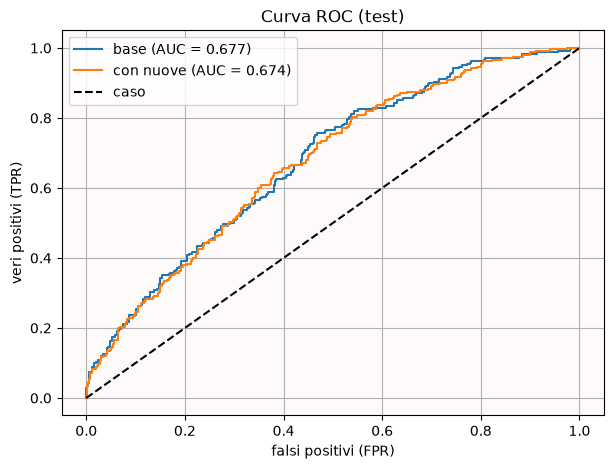

In [22]:
fig, ax = plt.subplots(figsize=(7, 5))
for nome, p in probs_test.items():
    fpr, tpr, _ = skl_metr.roc_curve(y_test, p)
    ax.plot(fpr, tpr, label=f"{nome} (AUC = {skl_metr.roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="caso")
ax.set_xlabel("falsi positivi (FPR)"); ax.set_ylabel("veri positivi (TPR)"); ax.set_title("Curva ROC (test)")
ax.set_facecolor("snow"); ax.legend(); ax.grid()
plt.show()

### Modello con tutte le variabili (senza selezione)
Tre versioni a confronto: tutte le variabili originali, tutte le originali + le 3 nuove, e il modello scelto col BIC + le 3 nuove forzate. Si guardano anche gli odds ratio delle variabili collineari e il VIF.

In [23]:
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

modelli = {
    "tutte le originali": POOL_BASE,
    "tutte le originali + 3 nuove": POOL_NUOVO,
    "scelta BIC (base) + 3 nuove": finali["base"]["variables"] + NUOVE,
}
righe = {}
for nome, cols in modelli.items():
    m = fit_logit(X_train[["const"] + cols], y_train)
    p_oof = prob_oof(cols)
    f1 = [skl_metr.f1_score(y_train, (p_oof >= t).astype(int)) for t in soglie]
    s = round(float(soglie[int(np.argmax(f1))]), 2)
    pt = m.predict(X_test[["const"] + cols]); pr = (pt >= s).astype(int)
    righe[nome] = {"n var": len(cols), "AIC": m.aic, "BIC": m.bic, "AUC cv": skl_metr.roc_auc_score(y_train, p_oof),
                   "AUC test": skl_metr.roc_auc_score(y_test, pt), "soglia": s, "recall": skl_metr.recall_score(y_test, pr),
                   "f-score": skl_metr.f1_score(y_test, pr), "phi-score": skl_metr.matthews_corrcoef(y_test, pr)}
pd.DataFrame(righe)

,tutte le originali,tutte le originali + 3 nuove,scelta BIC (base) + 3 nuove
n var,20.000,23.000,12.000
AIC,3682.715,3687.747,3675.773
BIC,3812.508,3836.081,3756.121
AUC cv,0.724,0.724,0.729
AUC test,0.680,0.680,0.677
soglia,0.250,0.270,0.250
recall,0.746,0.679,0.758
f-score,0.494,0.478,0.494
phi-score,0.247,0.223,0.246


In [24]:
m_tutte = fit_logit(X_train[["const"] + POOL_NUOVO], y_train)
chiave = NUOVE + ["Cost_without_study", "Family_background_Rich class", "Family_background_Middle class", "CGPA"]
t = pd.DataFrame({"coef": m_tutte.params, "OR": np.exp(m_tutte.params), "p-value": m_tutte.pvalues}).loc[chiave]
Xv = X_train[POOL_NUOVO].astype(float)
t["VIF"] = pd.Series([vif(Xv.values, i) for i in range(Xv.shape[1])], index=Xv.columns)
t

,coef,OR,p-value,VIF
cgpa_rel_semestre,0.406,1.501,0.336,107.373
costo_rel,0.023,1.023,0.846,6.684
isolato,0.002,1.002,0.992,2.528
Cost_without_study,0.415,1.514,0.011,10.687
Family_background_Rich class,-1.431,0.239,0.001,8.771
Family_background_Middle class,-0.403,0.668,0.016,3.309
CGPA,-0.673,0.510,0.112,107.483


**Come leggerlo**: con 240 depressi nel test, differenze di AUC di 0,01-0,02 sono rumore. Le nuove variabili sono utili solo se migliorano **sia** il BIC (che penalizza la complessità) **sia** l'AUC fuori campione. Altri riferimenti sul test (stessi studenti): albero base AUC 0,675, albero con 4 variabili 0,667, logistica originale 0,664.